Імпорти

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt

Завантаження даних і базова перевірка

In [2]:
train = pd.read_csv("application_train.csv")
test = pd.read_csv("application_test.csv")

print("Розмір train:", train.shape)
print("Розмір test:", test.shape)

print()

display(train.head())

Розмір train: (307511, 122)
Розмір test: (48744, 121)



,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Перевірка цільової змінної TARGET

In [3]:
print("Розподіл TARGET:")
print(train["TARGET"].value_counts())

print()

print("Розподіл TARGET у відсотках:")
print(train["TARGET"].value_counts(normalize=True) * 100)

Розподіл TARGET:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Розподіл TARGET у відсотках:
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


Перевірка типів даних

In [4]:
print("Типи даних:")
print(train.dtypes.value_counts())

Типи даних:
float64    65
int64      41
str        16
Name: count, dtype: int64


Перевірка пропущених значень

In [5]:
missing = train.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Кількість колонок з пропущеними значеннями:")
print(len(missing))

print()

display(missing.head(20))

Кількість колонок з пропущеними значеннями:
67



COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
dtype: int64

Пошук категоріальних ознак

In [6]:
categorical_cols = train.select_dtypes(include=["str"]).columns.tolist()

print("Кількість категоріальних ознак:")
print(len(categorical_cols))

print()

print("Категоріальні ознаки:")
print(categorical_cols)

Кількість категоріальних ознак:
16

Категоріальні ознаки:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


Підготовка даних

In [7]:
X = train.drop(columns=["TARGET", "SK_ID_CURR"])
y = train["TARGET"]

test_ids = test["SK_ID_CURR"].copy()

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)
print("Розмір test:", test.shape)

Розмір X: (307511, 120)
Розмір y: (307511,)
Розмір test: (48744, 121)


Обробка категоріальних ознак і пропущених значень


In [8]:
X_full = pd.concat([X, test.drop(columns=["SK_ID_CURR"])], axis=0)

X_full = pd.get_dummies(X_full, columns=X_full.select_dtypes(include=["str"]).columns)

X = X_full.iloc[:len(train)].copy()
test_processed = X_full.iloc[len(train):].copy()

print("Розмір X після кодування:", X.shape)
print("Розмір test після кодування:", test_processed.shape)

Розмір X після кодування: (307511, 244)
Розмір test після кодування: (48744, 244)


Заповнення пропущених числових значень

In [9]:
print("Кількість пропущених значень у train:")
print(X.isnull().sum().sum())

print()

print("Кількість пропущених значень у test:")
print(test_processed.isnull().sum().sum())

Кількість пропущених значень у train:
8388094

Кількість пропущених значень у test:
1285385


Розділення даних

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

medians = X_train.median()

X_train = X_train.fillna(medians)
X_valid = X_valid.fillna(medians)

X = X.fillna(medians)
test_processed = test_processed.fillna(medians)

print("Розмір X_train:", X_train.shape)
print("Розмір X_valid:", X_valid.shape)
print("Розмір y_train:", y_train.shape)
print("Розмір y_valid:", y_valid.shape)

Розмір X_train: (246008, 244)
Розмір X_valid: (61503, 244)
Розмір y_train: (246008,)
Розмір y_valid: (61503,)


Навчання моделі

In [11]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()

model.fit(X_train, y_train)

print("Модель навчено")

Модель навчено


Оцінка ROC-AUC

In [12]:
from sklearn.metrics import roc_auc_score

y_valid_proba = model.predict_proba(X_valid)[:, 1]

roc_auc = roc_auc_score(y_valid, y_valid_proba)

print("ROC-AUC:")
print(roc_auc)

ROC-AUC:
0.5347976480593915


Матриця помилок

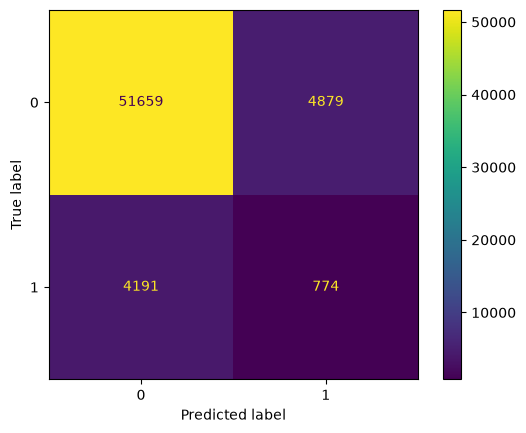

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_valid_pred = model.predict(X_valid)

cm = confusion_matrix(y_valid, y_valid_pred)

display_cm = ConfusionMatrixDisplay(confusion_matrix=cm)
display_cm.plot()

plt.show()

Аналіз помилок

In [14]:
tn, fp, fn, tp = cm.ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

print()

print("Загальна кількість помилок:")
print(fp + fn)

True Negative: 51659
False Positive: 4879
False Negative: 4191
True Positive: 774

Загальна кількість помилок:
9070


Модель правильно класифікувала 51659 об'єктів класу 0 та 774 об'єкти класу 1. При цьому отримано 4879 False Positive та 4191 False Negative прогнозів. Значення ROC-AUC = 0.5348 свідчить про низьку здатність базової моделі розрізняти класи.

Формування прогнозу для тестових даних

In [15]:
model.fit(X, y)

test_proba = model.predict_proba(test_processed)[:, 1]

print("Кількість прогнозів:")
print(len(test_proba))

Кількість прогнозів:
48744


Створення submission-файлу

In [16]:
submission = pd.DataFrame({
    "SK_ID_CURR": test_ids,
    "TARGET": test_proba
})

display(submission.head())

submission.to_csv("submission.csv", index=False)

print()
print("Файл submission.csv створено")

,SK_ID_CURR,TARGET
0,100001,0.0
1,100005,0.0
2,100013,0.0
3,100028,1.0
4,100038,0.0



Файл submission.csv створено


## 3 Лаб

Аналіз числових ознак

In [17]:
numeric_cols = train.select_dtypes(include=["number"]).columns.drop(
    ["TARGET", "SK_ID_CURR"]
)

print("Кількість числових ознак:", len(numeric_cols))

display(train[numeric_cols].describe())

Кількість числових ознак: 104


,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,-4986.120328,-2994.202373,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,3522.886321,1509.450419,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,-24672.000000,-7197.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,-7479.500000,-4299.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,-4504.000000,-3254.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,-2010.000000,-1720.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


Аналіз категоріальних ознак

In [18]:
categorical_cols = train.select_dtypes(include=["object", "str"]).columns

print("Кількість категоріальних ознак:", len(categorical_cols))

for col in categorical_cols[:5]:
    print()
    print(col)
    print(train[col].value_counts(normalize=True).head(10))

Кількість категоріальних ознак: 16

NAME_CONTRACT_TYPE
NAME_CONTRACT_TYPE
Cash loans         0.904787
Revolving loans    0.095213
Name: proportion, dtype: float64

CODE_GENDER
CODE_GENDER
F      0.658344
M      0.341643
XNA    0.000013
Name: proportion, dtype: float64

FLAG_OWN_CAR
FLAG_OWN_CAR
N    0.659892
Y    0.340108
Name: proportion, dtype: float64

FLAG_OWN_REALTY
FLAG_OWN_REALTY
Y    0.693673
N    0.306327
Name: proportion, dtype: float64

NAME_TYPE_SUITE
NAME_TYPE_SUITE
Unaccompanied      0.811596
Family             0.131112
Spouse, partner    0.037130
Children           0.010669
Other_B            0.005780
Other_A            0.002828
Group of people    0.000885
Name: proportion, dtype: float64


Аналіз пропущених значень

In [19]:
missing_percent = train.isnull().mean() * 100

missing_percent = missing_percent[missing_percent > 0].sort_values(
    ascending=False
)

print("Кількість ознак з пропусками:", len(missing_percent))

display(missing_percent.head(20))

Кількість ознак з пропусками: 67


COMMONAREA_MEDI             69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_AVG              69.872297
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
FLOORSMIN_MEDI              67.848630
FLOORSMIN_MODE              67.848630
FLOORSMIN_AVG               67.848630
YEARS_BUILD_MODE            66.497784
YEARS_BUILD_MEDI            66.497784
YEARS_BUILD_AVG             66.497784
OWN_CAR_AGE                 65.990810
LANDAREA_AVG                59.376738
LANDAREA_MEDI               59.376738
LANDAREA_MODE               59.376738
dtype: float64

Аналіз збалансованості класів

In [20]:
target_distribution = train["TARGET"].value_counts(normalize=True) * 100

print("Розподіл класів (%):")
print(target_distribution)

print()
print("Співвідношення класів:")
print(train["TARGET"].value_counts())

Розподіл класів (%):
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64

Співвідношення класів:
TARGET
0    282686
1     24825
Name: count, dtype: int64


Зв'язок числових ознак з TARGET

In [21]:
correlations = train.select_dtypes(include=["number"]).corr()["TARGET"]

correlations = correlations.drop(["TARGET", "SK_ID_CURR"])
correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

print("Ознаки з найбільшою кореляцією з TARGET:")

display(correlations.head(15))

Ознаки з найбільшою кореляцією з TARGET:


EXT_SOURCE_3                  -0.178919
EXT_SOURCE_2                  -0.160472
EXT_SOURCE_1                  -0.155317
DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
DAYS_ID_PUBLISH                0.051457
REG_CITY_NOT_WORK_CITY         0.050994
FLAG_EMP_PHONE                 0.045982
DAYS_EMPLOYED                 -0.044932
REG_CITY_NOT_LIVE_CITY         0.044395
FLAG_DOCUMENT_3                0.044346
FLOORSMAX_AVG                 -0.044003
FLOORSMAX_MEDI                -0.043768
Name: TARGET, dtype: float64

Зв'язок категоріальних ознак з TARGET

In [22]:
cols = ["CODE_GENDER", "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE"]

for col in cols:
    print("\n", col)
    
    result = train.groupby(col)["TARGET"].agg(["mean", "count"])
    result = result.sort_values("mean", ascending=False)

    display(result)


 CODE_GENDER


,mean,count
CODE_GENDER,,
M,0.101419,105059
F,0.069993,202448
XNA,0.000000,4



 NAME_EDUCATION_TYPE


,mean,count
NAME_EDUCATION_TYPE,,
Lower secondary,0.109277,3816
Secondary / secondary special,0.089399,218391
Incomplete higher,0.084850,10277
Higher education,0.053551,74863
Academic degree,0.018293,164



 NAME_INCOME_TYPE


,mean,count
NAME_INCOME_TYPE,,
Maternity leave,0.400000,5
Unemployed,0.363636,22
Working,0.095885,158774
Commercial associate,0.074843,71617
State servant,0.057550,21703
Pensioner,0.053864,55362
Businessman,0.000000,10
Student,0.000000,18


Створення нових ознак

Середня зовнішня оцінка кредитного ризику

In [23]:
train_new = train.copy()
test_new = test.copy()

ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]

train_new["EXT_SOURCE_MEAN"] = train_new[ext_cols].mean(axis=1)
test_new["EXT_SOURCE_MEAN"] = test_new[ext_cols].mean(axis=1)

display(train_new[ext_cols + ["EXT_SOURCE_MEAN"]].head())

,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,EXT_SOURCE_MEAN
0,0.083037,0.262949,0.139376,0.161787
1,0.311267,0.622246,NaN,0.466757
2,NaN,0.555912,0.729567,0.642739
3,NaN,0.650442,NaN,0.650442
4,NaN,0.322738,NaN,0.322738


Вік клієнта та вікові групи

In [24]:
train_new["AGE_YEARS"] = -train_new["DAYS_BIRTH"] / 365
test_new["AGE_YEARS"] = -test_new["DAYS_BIRTH"] / 365

train_new["AGE_GROUP"] = (train_new["AGE_YEARS"] // 10).astype(int)
test_new["AGE_GROUP"] = (test_new["AGE_YEARS"] // 10).astype(int)

display(train_new[["DAYS_BIRTH", "AGE_YEARS", "AGE_GROUP"]].head())

,DAYS_BIRTH,AGE_YEARS,AGE_GROUP
0,-9461,25.920548,2
1,-16765,45.931507,4
2,-19046,52.180822,5
3,-19005,52.068493,5
4,-19932,54.608219,5


Стаж роботи клієнта

In [25]:
for data in [train_new, test_new]:
    data["EMPLOYED_YEARS"] = (
        -data["DAYS_EMPLOYED"].replace(365243, np.nan) / 365
    )

display(train_new[["DAYS_EMPLOYED", "EMPLOYED_YEARS"]].head())

,DAYS_EMPLOYED,EMPLOYED_YEARS
0,-637,1.745205
1,-1188,3.254795
2,-225,0.616438
3,-3039,8.326027
4,-3038,8.323288


Рівень освіти клієнта

In [26]:
education_map = {
    "Lower secondary": 1,
    "Secondary / secondary special": 2,
    "Incomplete higher": 3,
    "Higher education": 4,
    "Academic degree": 5
}

train_new["EDUCATION_LEVEL"] = train_new["NAME_EDUCATION_TYPE"].map(education_map)
test_new["EDUCATION_LEVEL"] = test_new["NAME_EDUCATION_TYPE"].map(education_map)

display(train_new[["NAME_EDUCATION_TYPE", "EDUCATION_LEVEL"]].head())

,NAME_EDUCATION_TYPE,EDUCATION_LEVEL
0,Secondary / secondary special,2
1,Higher education,4
2,Secondary / secondary special,2
3,Secondary / secondary special,2
4,Secondary / secondary special,2


Співвідношення кредиту до доходу

In [27]:
for data in [train_new, test_new]:
    data["CREDIT_INCOME_RATIO"] = (
        data["AMT_CREDIT"] / data["AMT_INCOME_TOTAL"].replace(0, np.nan)
    )

display(train_new[
    ["AMT_CREDIT", "AMT_INCOME_TOTAL", "CREDIT_INCOME_RATIO"]
].head())

,AMT_CREDIT,AMT_INCOME_TOTAL,CREDIT_INCOME_RATIO
0,406597.5,202500.0,2.007889
1,1293502.5,270000.0,4.790750
2,135000.0,67500.0,2.000000
3,312682.5,135000.0,2.316167
4,513000.0,121500.0,4.222222


Перевірка зв'язку нових ознак з TARGET

In [28]:
new_cols = [
    "EXT_SOURCE_MEAN",
    "AGE_YEARS",
    "AGE_GROUP",
    "EMPLOYED_YEARS",
    "EDUCATION_LEVEL",
    "CREDIT_INCOME_RATIO"
]

new_correlations = train_new[new_cols + ["TARGET"]].corr()["TARGET"]

print("Кореляція нових ознак з TARGET:")
display(new_correlations.drop("TARGET").sort_values())

Кореляція нових ознак з TARGET:


EXT_SOURCE_MEAN       -0.222052
AGE_YEARS             -0.078239
AGE_GROUP             -0.075873
EMPLOYED_YEARS        -0.074958
EDUCATION_LEVEL       -0.056872
CREDIT_INCOME_RATIO   -0.007727
Name: TARGET, dtype: float64

Найбільшу кореляцію з TARGET має EXT_SOURCE_MEAN (-0.2221), що перевищує кореляції окремих EXT_SOURCE. Вік, робочий стаж та рівень освіти також мають від'ємну кореляцію, тобто зі збільшенням цих показників частка неповернення кредитів зменшується. CREDIT_INCOME_RATIO має дуже слабку кореляцію (-0.0077)

Перевірка нових ознак

In [29]:
X_new = X.copy()
test_new_processed = test_processed.copy()

for col in new_cols:
    X_new[col] = train_new[col]
    test_new_processed[col] = test_new[col]

medians_new = X_new.loc[X_train.index, new_cols].median()

X_new[new_cols] = X_new[new_cols].fillna(medians_new)
test_new_processed[new_cols] = test_new_processed[new_cols].fillna(medians_new)

print("Розмір X:", X_new.shape)
print("Розмір test:", test_new_processed.shape)

print()

print("Кількість пропусків у X:", X_new.isnull().sum().sum())
print("Кількість пропусків у test:", test_new_processed.isnull().sum().sum())

Розмір X: (307511, 250)
Розмір test: (48744, 250)

Кількість пропусків у X: 0
Кількість пропусків у test: 0


Перевірка нових ознак

In [30]:
results = {"Baseline": roc_auc}

feature_groups = {
    "EXT_SOURCE_MEAN": ["EXT_SOURCE_MEAN"],
    "AGE_YEARS": ["AGE_YEARS"],
    "AGE_GROUP": ["AGE_GROUP"],
    "EMPLOYED_YEARS": ["EMPLOYED_YEARS"],
    "EDUCATION_LEVEL": ["EDUCATION_LEVEL"],
    "CREDIT_INCOME_RATIO": ["CREDIT_INCOME_RATIO"],
    "All Features": new_cols
}

for name, cols in feature_groups.items():
    X_temp = X_new[X.columns.tolist() + cols]

    X_train_new = X_temp.loc[X_train.index]
    X_valid_new = X_temp.loc[X_valid.index]

    model_new = DecisionTreeClassifier()
    model_new.fit(X_train_new, y_train)

    y_proba_new = model_new.predict_proba(X_valid_new)[:, 1]
    auc = roc_auc_score(y_valid, y_proba_new)

    results[name] = auc

    print(name, "ROC-AUC:", round(auc, 4))

EXT_SOURCE_MEAN ROC-AUC: 0.54
AGE_YEARS ROC-AUC: 0.5394
AGE_GROUP ROC-AUC: 0.5384
EMPLOYED_YEARS ROC-AUC: 0.5372
EDUCATION_LEVEL ROC-AUC: 0.5367
CREDIT_INCOME_RATIO ROC-AUC: 0.5357
All Features ROC-AUC: 0.5361


Порівняння результатів моделей

In [31]:
comparison = pd.DataFrame({
    "Model": list(results.keys()),
    "ROC-AUC": list(results.values())
})

comparison["Difference"] = comparison["ROC-AUC"] - roc_auc

comparison = comparison.sort_values("ROC-AUC", ascending=False)

display(comparison)

,Model,ROC-AUC,Difference
1,EXT_SOURCE_MEAN,0.539972,0.005174
2,AGE_YEARS,0.539441,0.004644
3,AGE_GROUP,0.538440,0.003643
4,EMPLOYED_YEARS,0.537202,0.002404
5,EDUCATION_LEVEL,0.536665,0.001867
7,All Features,0.536059,0.001261
6,CREDIT_INCOME_RATIO,0.535654,0.000857
0,Baseline,0.534798,0.000000


Аналіз впливу нових ознак

In [32]:
print("Найбільший приріст ROC-AUC:")
display(comparison.head(4))

print()
print("Найменший приріст ROC-AUC:")
display(comparison.tail(3))

Найбільший приріст ROC-AUC:


,Model,ROC-AUC,Difference
1,EXT_SOURCE_MEAN,0.539972,0.005174
2,AGE_YEARS,0.539441,0.004644
3,AGE_GROUP,0.538440,0.003643
4,EMPLOYED_YEARS,0.537202,0.002404



Найменший приріст ROC-AUC:


,Model,ROC-AUC,Difference
7,All Features,0.536059,0.001261
6,CREDIT_INCOME_RATIO,0.535654,0.000857
0,Baseline,0.534798,0.000000


Визначення найкращої моделі

In [33]:
best_name = comparison.iloc[0]["Model"]
best_auc = comparison.iloc[0]["ROC-AUC"]

print("Найкраща модель:", best_name)
print("ROC-AUC:", round(best_auc, 4))

Найкраща модель: EXT_SOURCE_MEAN
ROC-AUC: 0.54


Аналіз важливості ознак

In [34]:
if best_name == "Baseline":
    best_cols = X.columns.tolist()
else:
    best_cols = X.columns.tolist() + feature_groups[best_name]

X_train_best = X_new.loc[X_train.index, best_cols]
X_valid_best = X_new.loc[X_valid.index, best_cols]

best_model = DecisionTreeClassifier()
best_model.fit(X_train_best, y_train)

importance = pd.Series(
    best_model.feature_importances_,
    index=best_cols
)

importance = importance.sort_values(ascending=False)

print("Найважливіші ознаки:")
display(importance.head(15))

Найважливіші ознаки:


EXT_SOURCE_MEAN               0.095199
DAYS_REGISTRATION             0.041760
DAYS_ID_PUBLISH               0.041642
DAYS_BIRTH                    0.041459
EXT_SOURCE_2                  0.040473
DAYS_EMPLOYED                 0.034101
AMT_ANNUITY                   0.033671
EXT_SOURCE_3                  0.032768
DAYS_LAST_PHONE_CHANGE        0.032375
REGION_POPULATION_RELATIVE    0.028068
AMT_INCOME_TOTAL              0.025419
HOUR_APPR_PROCESS_START       0.023452
AMT_CREDIT                    0.022995
EXT_SOURCE_1                  0.020296
AMT_GOODS_PRICE               0.019147
dtype: float64

Порівняння важливості нових ознак

In [38]:
all_cols = X.columns.tolist() + new_cols

model_all = DecisionTreeClassifier()
model_all.fit(X_new.loc[X_train.index, all_cols], y_train)

all_importance = pd.Series(
    model_all.feature_importances_,
    index=all_cols
)

new_importance = all_importance[new_cols].sort_values(ascending=False)

print("Важливість нових ознак:")
display(new_importance)

Важливість нових ознак:


EXT_SOURCE_MEAN        0.094389
CREDIT_INCOME_RATIO    0.032555
AGE_YEARS              0.022330
EMPLOYED_YEARS         0.022050
EDUCATION_LEVEL        0.003514
AGE_GROUP              0.003007
dtype: float64

Навчання фінальної моделі

In [36]:
X_final = X_new[best_cols]
test_final = test_new_processed[best_cols]

final_model = DecisionTreeClassifier()
final_model.fit(X_final, y)

test_proba_new = final_model.predict_proba(test_final)[:, 1]

print("Кількість прогнозів:")
print(len(test_proba_new))

Кількість прогнозів:
48744


Створення submission-файлу

In [37]:
submission_new = pd.DataFrame({
    "SK_ID_CURR": test_ids,
    "TARGET": test_proba_new
})

display(submission_new.head())

submission_new.to_csv("submission_lab3.csv", index=False)

print("Файл створено")

,SK_ID_CURR,TARGET
0,100001,0.0
1,100005,0.0
2,100013,0.0
3,100028,0.0
4,100038,0.0


Файл створено
